# 03 — Musanga-dependent SAM1 crown segmentation errors

**Repository** `kvanoost/Musanga` · branch `v2` · `Crown/03_Musanga_SAM1_Error_Association.ipynb`.

**Research question:** Are SAM1 crown detection, merging and spatial canopy omissions associated with predicted *Musanga* abundance, after accounting for crown size and ROI?

**Mandatory source:** the **original U-Net Baego probability raster** inside `KVO_work/KVO_04_final_multisite/probability_maps/`. The `probability_maps_M1_feathered_v2/` and any M1 outputs are **explicitly prohibited**. The notebook identifies the raster and checks coverage, CRS, raw integer encoding, numeric range and nodata before analysis; it never runs a model.

The six consistent SAM1 predictions are read from `V2/Crown/sam1_core_centroid_halo40_v2/`. Reference crowns are Kristof's annotations ≥5 m². Object-level matches use the exact ≥0.50 one-to-one polygon IoU criterion from Notebook 02; matched/unmatched is not the same as biologically detected/missed. All findings are **associations**, not evidence that species causes a SAM failure.

**Runtime:** CPU. **Outputs:** `V2/Crown/musanga_sam1_diagnostics/`. Original rasters and crowns are read-only.

## 01 — Use the original **FULL Baego** probability raster

The original model has both a restricted `Baego_musanga_probability_uint16.tif` and a full-mosaic `Baego_musanga_probability_uint16_FULL.tif`. This notebook explicitly selects **FULL** from `KVO_04_final_multisite/probability_maps/` (never from `probability_maps_M1_feathered_v2`).

The probability is stored as **uint16**, not floating-point 0–1. The decoding divisor is displayed in Section 01 and audited in Section 03 before interpretation.

In [1]:
# 01 — Source validation (CPU only)
!pip -q install geopandas rasterio shapely scipy statsmodels

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds, Window
from rasterio.features import geometry_mask
from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import unary_union
from shapely import make_valid
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import statsmodels.api as sm
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/Colab Notebooks/Musanga")
DATA = ROOT/"data/Geo_Ref"
KVO04 = ROOT/"KVO_work/KVO_04_final_multisite"
ORIGINAL_PROB_DIR = KVO04/"probability_maps"
M1_PROB_DIR = KVO04/"probability_maps_M1_feathered_v2"  # deliberately NEVER used
ORIGINAL_BAEGO_PROBABILITY = ORIGINAL_PROB_DIR/"Baego_musanga_probability_uint16_FULL.tif"
# The original model exports integer-encoded probabilities. Confirm the stored
# encoding before analysis. The source appears to use a 0..10000 integer encoding. Validate raw values.
UINT16_DIVISOR = 10000.0
RGB = DATA/"Baego_georef.tif"
ROI_FILE = DATA/"Annotations/ROI_Crowns_Kvo.shp"
REF_FILE = DATA/"Annotations/Crown_Kristof.shp"
SAM_DIR = ROOT/"V2/Crown/sam1_core_centroid_halo40_v2"
OUT = ROOT/"V2/Crown/musanga_sam1_diagnostics"
ROIS=tuple(range(6))
METHOD="nms_060"
MIN_REF_AREA=5.0
MATCH_IOU=0.50
MIN_ASSOC_COVERAGE=0.25

for required in (RGB,ROI_FILE,REF_FILE,SAM_DIR,ORIGINAL_PROB_DIR):
    if not required.exists(): raise FileNotFoundError(required)
for i in ROIS:
    if not (SAM_DIR/f"roi{i}_{METHOD}.gpkg").exists():
        raise FileNotFoundError(SAM_DIR/f"roi{i}_{METHOD}.gpkg")
if ORIGINAL_BAEGO_PROBABILITY is None:
    all_tif=sorted(p for p in ORIGINAL_PROB_DIR.rglob("*")
                   if p.is_file() and p.suffix.lower() in (".tif",".tiff"))
    # Filter carefully; do not select a probability map from a different study site.
    candidates=[p for p in all_tif if "baego" in p.name.lower()
                and not any(x in p.name.lower() for x in ("_m1","fine_tuned","finetuned"))]
    print("Original probability candidates:",*[str(p) for p in candidates],sep="\n  ")
    if len(candidates)!=1:
        print("All original-folder TIFFs:",*[str(p) for p in all_tif],sep="\n  ")
        raise RuntimeError(
            "Cannot unambiguously select original Baego probability TIFF. "
            "Specify ORIGINAL_BAEGO_PROBABILITY using a VERIFIED file inside ORIGINAL_PROB_DIR.")
    PROB_FILE=candidates[0]
else:
    PROB_FILE=Path(ORIGINAL_BAEGO_PROBABILITY)
if not PROB_FILE.is_file() or ORIGINAL_PROB_DIR.resolve() not in PROB_FILE.resolve().parents:
    raise ValueError("Probability file must exist INSIDE original KVO_04 probability_maps directory")
if "m1" in PROB_FILE.name.lower() or "fine_tuned" in PROB_FILE.name.lower():
    raise ValueError("Refusing an M1/fine-tuned probability raster")
with rasterio.open(RGB) as ds:
    CRS=ds.crs
    BOUNDS=ds.bounds
with rasterio.open(PROB_FILE) as ds:
    print("ORIGINAL probability raster:",PROB_FILE)
    print("Metadata: CRS=",ds.crs,"bands=",ds.count,"dtype=",ds.dtypes,
          "nodata=",ds.nodata,"resolution=",ds.res,"bounds=",ds.bounds)
    if ds.count!=1: raise ValueError("Need one probability band; inspect source explicitly")
    if ds.crs is None: raise ValueError("Probability raster lacks CRS")
    print("Scale/offset metadata:",ds.scales,ds.offsets,"tags:",ds.tags(1))
if CRS is None or not CRS.is_projected:
    raise ValueError("Baego raster needs projected metre-based CRS")
OUT.mkdir(parents=True,exist_ok=True)
print("Output:",OUT)

Mounted at /content/drive
ORIGINAL probability raster: /content/drive/MyDrive/Colab Notebooks/Musanga/KVO_work/KVO_04_final_multisite/probability_maps/Baego_musanga_probability_uint16_FULL.tif
Metadata: CRS= EPSG:32635 bands= 1 dtype= ('uint16',) nodata= 65535.0 resolution= (0.07999999999999985, 0.07999999999999999) bounds= BoundingBox(left=407183.19906, bottom=78043.59094000001, right=414380.55906, top=82946.87094000001)
Scale/offset metadata: (1.0,) (0.0,) tags: {}
Output: /content/drive/MyDrive/Colab Notebooks/Musanga/V2/Crown/musanga_sam1_diagnostics


## 02 — Load six ROI polygons, reference annotations and SAM1 crowns

Assign Baego's projected CRS to the reference shapefile **only when its raw coordinates overlap the Baego RGB bounds** (same safeguard as Notebook 00). The original probability raster may have a distinct CRS and is reprojected **on demand** for ROI-level sampling, without altering stored files.

In [2]:
# 02 — Geometries and reprojection-safe probability sampling
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

def polygonal(g):
    if g is None or g.is_empty:return Polygon()
    if not g.is_valid:g=make_valid(g)
    if isinstance(g,(Polygon,MultiPolygon)):return g
    parts=[x for x in getattr(g,"geoms",[])
           if isinstance(x,(Polygon,MultiPolygon)) and not x.is_empty]
    return unary_union(parts) if parts else Polygon()

def load_projected(path):
    g=gpd.read_file(path)
    g=g.loc[g.geometry.notna() & ~g.geometry.is_empty].copy().reset_index(drop=True)
    if g.crs is None:
        bb, rb = g.total_bounds,tuple(BOUNDS)
        if not (bb[2]>=rb[0] and bb[0]<=rb[2] and bb[3]>=rb[1] and bb[1]<=rb[3]):
            raise ValueError(f"Missing CRS; coordinates do not overlap RGB: {path}")
        print("Assigning matching Baego RGB CRS to",path.name)
        g=g.set_crs(CRS)
    else:g=g.to_crs(CRS)
    g["geometry"]=gpd.GeoSeries([polygonal(x) for x in g.geometry],index=g.index,crs=CRS)
    return g.loc[~g.geometry.is_empty].reset_index(drop=True)

rois=load_projected(ROI_FILE)
assert len(rois)==6
refs=load_projected(REF_FILE)
refs=refs.loc[refs.geometry.area>=MIN_REF_AREA].reset_index(drop=True)
sam={r:load_projected(SAM_DIR/f"roi{r}_{METHOD}.gpkg") for r in ROIS}
print("Reference crowns (whole Baego):",len(refs))
display(pd.DataFrame([
    {"ROI":r,"reference_inside":int(refs.geometry.centroid.within(rois.geometry.iloc[r]).sum()),
     "SAM_inside":int(sam[r].geometry.centroid.within(rois.geometry.iloc[r]).sum())}
    for r in ROIS]))

Assigning matching Baego RGB CRS to Crown_Kristof.shp
Reference crowns (whole Baego): 1151


,ROI,reference_inside,SAM_inside
0,0,175,129
1,1,157,116
2,2,205,176
3,3,218,173
4,4,213,127
5,5,178,159


## 03 — Verify and decode original integer probabilities

**Correction:** The first run divided original Baego integer probabilities by 65,535, yielding an implausible ceiling of ~0.1525 in every ROI. This implies raw maximum ~9,994, consistent with a **0–10,000 export scale**. Notebook 03 therefore now uses **10,000**, with a mandatory raw-range validation before downstream calculations.

This is an inferred encoding from the observed raw values, **not yet independently verified from the generating script**. Inspect the export code or stored scale tags if available. All source rasters remain untouched. The fixed scaling preserves rankings and quartiles but changes probability means and GLM coefficient units.

In [3]:
# 03 — ROI-based raster check; original probability must be 0..1
with rasterio.open(PROB_FILE) as src:
    with WarpedVRT(src,crs=CRS,resampling=Resampling.nearest) as ds:
        PROB_RES=ds.res
        checks=[]
        if ds.count != 1: raise ValueError("Expected a single-band probability raster")
        for roi in ROIS:
            region=rois.geometry.iloc[roi]
            win=from_bounds(*region.bounds,transform=ds.transform).round_offsets().round_lengths()
            win=win.intersection(Window(0,0,ds.width,ds.height))
            arr=ds.read(1,window=win,masked=True)
            tx=ds.window_transform(win)
            mask=geometry_mask([region],out_shape=arr.shape,transform=tx,invert=True)
            valid=mask & ~np.ma.getmaskarray(arr) & np.isfinite(arr.data)
            raw_vals=arr.data[valid]
            raw_max=float(raw_vals.max()) if len(raw_vals) else np.nan
            vals=raw_vals
            if np.issubdtype(arr.dtype,np.integer):
                vals=vals.astype(np.float64)/UINT16_DIVISOR
            else:
                vals=vals.astype(np.float64)
            if len(vals):
                lo,hi=np.quantile(vals,[0.01,0.99])
                minval,maxval=float(vals.min()),float(vals.max())
            else:lo=hi=minval=maxval=np.nan
            checks.append({"ROI":roi,"valid_roi_pixels":int(valid.sum()),
                           "roi_pixels":int(mask.sum()),
                           "valid_pct":100*valid.sum()/max(int(mask.sum()),1),
                           "raw_max":raw_max,
                           "min":minval,"p01":lo,"p99":hi,"max":maxval})
        QA=pd.DataFrame(checks)
print("Probability raster in Baego CRS:",PROB_RES)
print("Decoding assumed 0..10000 integer-scale probabilities, divisor:",UINT16_DIVISOR)
print("Observed maximum raw pixel value:", QA["raw_max"].max())
print("Verify divisor against original U-Net export script before publication.")
display(QA.round(4))
if (QA.valid_pct<95).any():
    raise RuntimeError("Original probability raster has <95% valid pixels in at least one ROI")
if QA["raw_max"].max()>10000 or QA["raw_max"].min()<0:
    raise ValueError("Original integer raster has values outside expected 0..10000 encoding")
if QA["min"].min()<-.001 or QA["max"].max()>1.001:
    raise ValueError("Decoded probability values are not in [0,1]. Inspect TIFF encoding and UINT16_DIVISOR.")
QA.to_csv(OUT/"03_original_probability_coverage_QA.csv",index=False)

Probability raster in Baego CRS: (0.07999999999999985, 0.07999999999999999)
Decoding assumed 0..10000 integer-scale probabilities, divisor: 10000.0
Observed maximum raw pixel value: 9995.0
Verify divisor against original U-Net export script before publication.


,ROI,valid_roi_pixels,roi_pixels,valid_pct,raw_max,min,p01,p99,max
0,0,2850312,2850312,100.0,9985.0,0.0001,0.0009,0.9868,0.9985
1,1,2759028,2759028,100.0,9985.0,0.0029,0.0101,0.9902,0.9985
2,2,3062439,3062439,100.0,9995.0,0.0063,0.0208,0.9971,0.9995
3,3,2809075,2809075,100.0,9995.0,0.0027,0.0099,0.9990,0.9995
4,4,3375097,3375097,100.0,9995.0,0.0050,0.0221,0.9990,0.9995
5,5,3337291,3337291,100.0,9995.0,0.0024,0.0124,0.9961,0.9995


## 04 — Crown-level Musanga probability and SAM1 match status

Compute the area-weighted mean **original U-Net Musanga probability** inside each reference crown; match Kristof vs NMS crowns via Hungarian one-to-one **IoU ≥0.50** separately by ROI. Reference crowns are included if their centroids fall inside the ROI.

A reference crown with no IoU ≥0.50 match is **unmatched**, not necessarily entirely undetected. Additional candidate associations (merges/splits) use ≥25% of reference crown area covered by one prediction. This is a descriptive geometric heuristic.

Crown probability and size are preserved as continuous predictors; the analysis never converts high probability into a categorical confirmed species label.

In [4]:
# 04 — Crown matching and original probability extraction
from rasterio.features import geometry_mask

def polygon_mean_probability(ds,poly):
    if poly is None or poly.is_empty:return np.nan
    try:
        win=from_bounds(*poly.bounds,transform=ds.transform).round_offsets().round_lengths()
        win=win.intersection(Window(0,0,ds.width,ds.height))
        if win.width<1 or win.height<1:return np.nan
        a=ds.read(1,window=win,masked=True)
        m=geometry_mask([poly],out_shape=a.shape,
                        transform=ds.window_transform(win),invert=True)
        valid=m & ~np.ma.getmaskarray(a) & np.isfinite(a.data)
        if not valid.any():return np.nan
        v=a.data[valid].astype(np.float64)
        if np.issubdtype(a.dtype,np.integer):v=v/UINT16_DIVISOR
        return float(v.mean())
    except (ValueError, rasterio.errors.WindowError):return np.nan

def crown_records_for_roi(roi,ds):
    region=rois.geometry.iloc[roi]
    truth=list(refs.loc[refs.geometry.centroid.within(region)].geometry)
    guess=list(sam[roi].loc[sam[roi].geometry.centroid.within(region)].geometry)
    nr,npred=len(truth),len(guess)
    intersections=np.zeros((nr,npred),dtype=float)
    iou=np.zeros_like(intersections)
    for i,a in enumerate(truth):
        for j,b in enumerate(guess):
            if not a.intersects(b):continue
            v=a.intersection(b).area
            intersections[i,j]=v
            union=a.area+b.area-v
            iou[i,j]=v/union if union else 0.
    pairs=[]
    if nr and npred:
        cost=np.zeros((nr+npred,nr+npred))
        cost[:nr,:npred]=-np.where(iou>=MATCH_IOU,iou,0.)
        ia,ib=linear_sum_assignment(cost)
        pairs=[(int(i),int(j)) for i,j in zip(ia,ib)
               if i<nr and j<npred and iou[i,j]>=MATCH_IOU]
    matched={i for i,j in pairs}
    areas=np.array([x.area for x in truth])
    assoc=intersections/np.maximum(areas[:,None],1e-12)>=MIN_ASSOC_COVERAGE
    rows=[]
    for i,g in enumerate(truth):
        rows.append({"ROI":roi,"ref_local_id":i,"ref_area_m2":g.area,
                     "log_area":np.log(g.area),"matched_iou_ge_0_5":int(i in matched),
                     "best_pred_IoU":float(iou[i].max()) if npred else 0.,
                     "n_significant_SAM_overlaps":int(assoc[i].sum()) if npred else 0,
                     "potential_split":int(assoc[i].sum()>=2) if npred else 0,
                     "potential_merge":int(any(assoc[:,j].sum()>=2 for j in np.where(assoc[i])[0])) if npred else 0,
                     "musanga_mean_probability":polygon_mean_probability(ds,g),
                     "geometry":g})
    return rows

with rasterio.open(PROB_FILE) as original:
    with WarpedVRT(original,crs=CRS,resampling=Resampling.nearest) as prob:
        REF_ROWS=[]
        for roi in ROIS:
            REF_ROWS.extend(crown_records_for_roi(roi,prob))
            print(f"ROI {roi}: {sum(x['ROI']==roi for x in REF_ROWS)} reference crowns sampled",flush=True)
REF_CROWNS=gpd.GeoDataFrame(REF_ROWS,geometry="geometry",crs=CRS)
REF_TABLE=pd.DataFrame(REF_CROWNS.drop(columns="geometry"))
print("Missing mean probability:",REF_TABLE.musanga_mean_probability.isna().sum())
display(REF_TABLE.groupby(["ROI","matched_iou_ge_0_5"],as_index=False)
        .agg(n=("ref_area_m2","size"),
             median_area_m2=("ref_area_m2","median"),
             musanga_mean=("musanga_mean_probability","mean"),
             musanga_median=("musanga_mean_probability","median")).round(3))
REF_TABLE.to_csv(OUT/"03_reference_crowns_probability_and_matching.csv",index=False)

ROI 0: 175 reference crowns sampled
ROI 1: 157 reference crowns sampled
ROI 2: 205 reference crowns sampled
ROI 3: 218 reference crowns sampled
ROI 4: 213 reference crowns sampled
ROI 5: 178 reference crowns sampled
Missing mean probability: 0


,ROI,matched_iou_ge_0_5,n,median_area_m2,musanga_mean,musanga_median
0,0,0,89,28.276,0.228,0.121
1,0,1,86,48.391,0.253,0.143
2,1,0,78,32.233,0.400,0.241
3,1,1,79,62.645,0.349,0.227
4,2,0,98,24.813,0.621,0.728
5,2,1,107,62.401,0.552,0.572
6,3,0,100,21.042,0.647,0.808
7,3,1,118,44.677,0.538,0.569
8,4,0,134,34.376,0.923,0.986
9,4,1,79,46.415,0.798,0.921


## 05 — Does Musanga probability explain crown matching?

Report matched vs unmatched crown probability **within every ROI**, then compare matching rates by pooled Musanga-probability quartiles. Check whether the direction of association is consistent across ROIs.

Fit a **descriptive** logistic GLM: `matched ~ Musanga probability + log crown area + ROI fixed effects`. This isolates a *within-ROI, size-adjusted association* but **does not establish causation or spatially independent statistical significance** (only six spatial regions; neighboring crowns are correlated). No p-value is interpreted as definitive ecological evidence.

In [5]:
# 05 — Quartiles, ROI stratification, and size-adjusted descriptive model
ANALYSIS=REF_TABLE.dropna(subset=["musanga_mean_probability","log_area"]).copy()
if ANALYSIS.empty:raise RuntimeError("No valid probability samples.")
ANALYSIS["musanga_quartile"]=pd.qcut(ANALYSIS.musanga_mean_probability,
                                     q=4,duplicates="drop")
QUARTILES=ANALYSIS.groupby("musanga_quartile",observed=True).agg(
    n=("matched_iou_ge_0_5","size"),
    matched_rate=("matched_iou_ge_0_5","mean"),
    median_probability=("musanga_mean_probability","median"),
    median_area=("ref_area_m2","median")).reset_index()
print("=== Matching by continuous U-Net probability quartiles ===")
display(QUARTILES.round(3))
QUARTILES.to_csv(OUT/"03_probability_quartile_matching.csv",index=False)

PER_ROI=ANALYSIS.groupby(["ROI","matched_iou_ge_0_5"]).agg(
    n=("ref_area_m2","size"),mean_prob=("musanga_mean_probability","mean"),
    median_prob=("musanga_mean_probability","median"),
    median_area=("ref_area_m2","median")).reset_index()
display(PER_ROI.round(3))
PER_ROI.to_csv(OUT/"03_by_ROI_match_probability.csv",index=False)

X=pd.concat([ANALYSIS[["musanga_mean_probability","log_area"]],
             pd.get_dummies(ANALYSIS.ROI.astype(str),prefix="ROI",drop_first=True,dtype=float)],axis=1)
X=sm.add_constant(X).astype(float)
y=ANALYSIS.matched_iou_ge_0_5.astype(float)
fit=sm.GLM(y,X,family=sm.families.Binomial()).fit()
beta=float(fit.params["musanga_mean_probability"])
print("Size- and ROI-adjusted odds ratio for matching per +0.25 probability:",
      round(float(np.exp(beta*0.25)),3))
print("Association only: this does not prove species-specific model failure.")
display(pd.DataFrame({"coefficient":fit.params,"SE_naive":fit.bse}).round(3))
with open(OUT/"03_descriptive_GLM.txt","w") as f:
    f.write("Descriptive analysis only; naive SE ignores spatial dependence.\n")
    f.write(str(fit.summary()))

=== Matching by continuous U-Net probability quartiles ===


,musanga_quartile,n,matched_rate,median_probability,median_area
0,"(0.00135, 0.134]",287,0.599,0.066,56.024
1,"(0.134, 0.542]",286,0.552,0.282,39.649
2,"(0.542, 0.926]",286,0.437,0.787,25.657
3,"(0.926, 0.999]",287,0.429,0.986,44.150


,ROI,matched_iou_ge_0_5,n,mean_prob,median_prob,median_area
0,0,0,89,0.228,0.121,28.276
1,0,1,86,0.253,0.143,48.391
2,1,0,78,0.400,0.241,32.233
3,1,1,79,0.349,0.227,62.645
4,2,0,98,0.621,0.728,24.813
5,2,1,107,0.552,0.572,62.401
6,3,0,100,0.647,0.808,21.042
7,3,1,118,0.538,0.569,44.677
8,4,0,134,0.923,0.986,34.376
9,4,1,79,0.798,0.921,46.415


Size- and ROI-adjusted odds ratio for matching per +0.25 probability: 0.898
Association only: this does not prove species-specific model failure.


,coefficient,SE_naive
const,-2.939,0.329
musanga_mean_probability,-0.432,0.209
log_area,0.823,0.076
ROI_1,-0.022,0.239
ROI_2,0.263,0.234
ROI_3,0.508,0.232
ROI_4,-0.332,0.261
ROI_5,0.358,0.234


## 06 — Is reference-only canopy disproportionately Musanga-like?

Use the same exact vector canopy footprint decomposition as Notebook 02. For each ROI, sample the original U-Net probability raster under **reference-only**, **SAM-only** and **agreement** areas. Because these polygon sets can be narrow, values are sampled on the raster grid with the valid-data mask; empty geometries are reported as missing.

The relevant comparison is **Musanga probability within the reference-only canopy versus matched canopy**. That is a spatial association, not a verified species count.

In [6]:
# 06 — Canopy-overlap categories versus original Musanga probability
def clipped_union(gdf,region):
    polys=[polygonal(g.intersection(region)) for g in
           gdf.loc[gdf.geometry.intersects(region)].geometry]
    polys=[p for p in polys if not p.is_empty and p.area>0]
    return polygonal(unary_union(polys)) if polys else Polygon()

def sample_category(ds,geometry,roi):
    if geometry.is_empty:return dict(valid_pixels=0,mean_prob=np.nan,median_prob=np.nan)
    region=rois.geometry.iloc[roi]
    win=from_bounds(*region.bounds,transform=ds.transform).round_offsets().round_lengths()
    win=win.intersection(Window(0,0,ds.width,ds.height))
    a=ds.read(1,window=win,masked=True)
    mask=geometry_mask([geometry],out_shape=a.shape,transform=ds.window_transform(win),invert=True)
    good=mask & ~np.ma.getmaskarray(a) & np.isfinite(a.data)
    v=a.data[good].astype(np.float64)
    if np.issubdtype(a.dtype,np.integer):v=v/UINT16_DIVISOR
    return dict(valid_pixels=int(len(v)),
                mean_prob=float(v.mean()) if len(v) else np.nan,
                median_prob=float(np.median(v)) if len(v) else np.nan)

with rasterio.open(PROB_FILE) as original:
    with WarpedVRT(original,crs=CRS,resampling=Resampling.nearest) as prob:
        results=[]
        for roi in ROIS:
            region=rois.geometry.iloc[roi]
            rt=clipped_union(refs,region)
            ps=clipped_union(sam[roi],region)
            geom_types={"agreement":polygonal(rt.intersection(ps)),
                        "reference_only":polygonal(rt.difference(ps)),
                        "sam_only":polygonal(ps.difference(rt))}
            for label,shape in geom_types.items():
                results.append({"ROI":roi,"category":label,
                                "vector_area_pct_ROI":100*shape.area/region.area,
                                **sample_category(prob,shape,roi)})
CANOPY_SPECIES=pd.DataFrame(results)
display(CANOPY_SPECIES.round(3))
CANOPY_SPECIES.to_csv(OUT/"03_canopy_spatial_categories_probability.csv",index=False)

,ROI,category,vector_area_pct_ROI,valid_pixels,mean_prob,median_prob
0,0,agreement,52.863,1506887,0.165,0.041
1,0,reference_only,13.983,398494,0.160,0.056
2,0,sam_only,12.156,346348,0.215,0.087
3,1,agreement,49.293,1360113,0.333,0.148
4,1,reference_only,13.705,378140,0.342,0.197
5,1,sam_only,12.165,335563,0.364,0.232
6,2,agreement,47.329,1449444,0.525,0.512
7,2,reference_only,13.538,414439,0.549,0.596
8,2,sam_only,12.180,372958,0.568,0.612
9,3,agreement,58.926,1655388,0.425,0.212


## 07 — Interpretation plots and ROI 4 visual inspection

Visualize the association directly: original Musanga probability versus reference-crown matching, and ROI 4 reference crowns coloured by the **original probability** with unmatched crowns outlined. Plot locations in the same projected coordinate system as the Baego RGB.

Do not equate high U-Net probability with verified species identity. An elevated Musanga probability among unmatched crowns would support a **targeted annotation audit** before making a species-dependent segmentation claim.

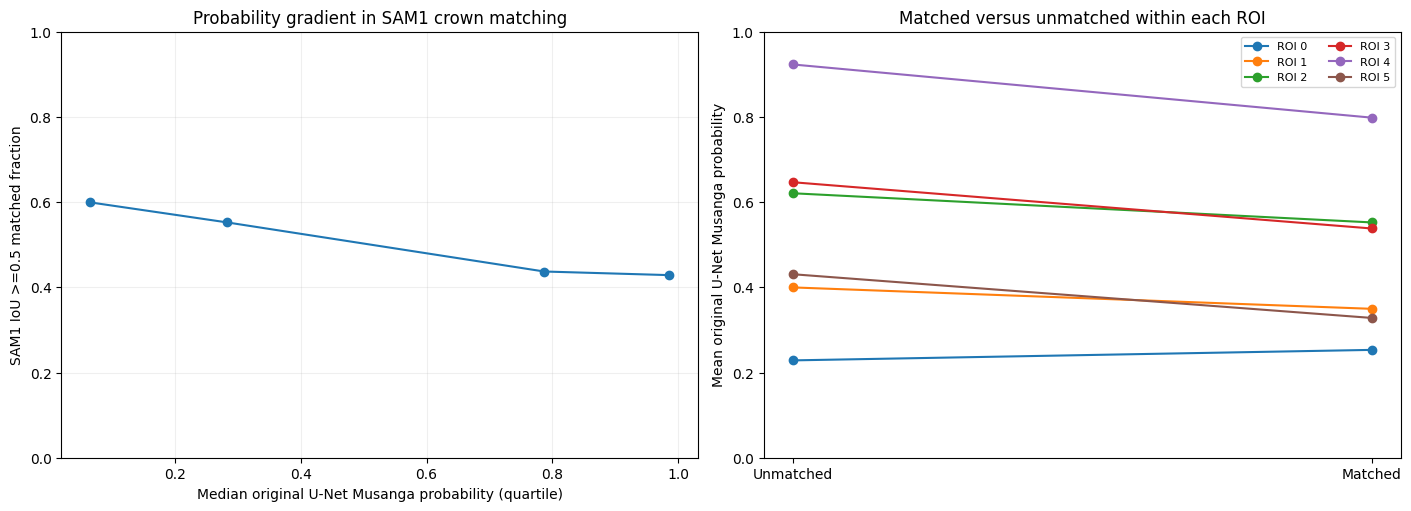

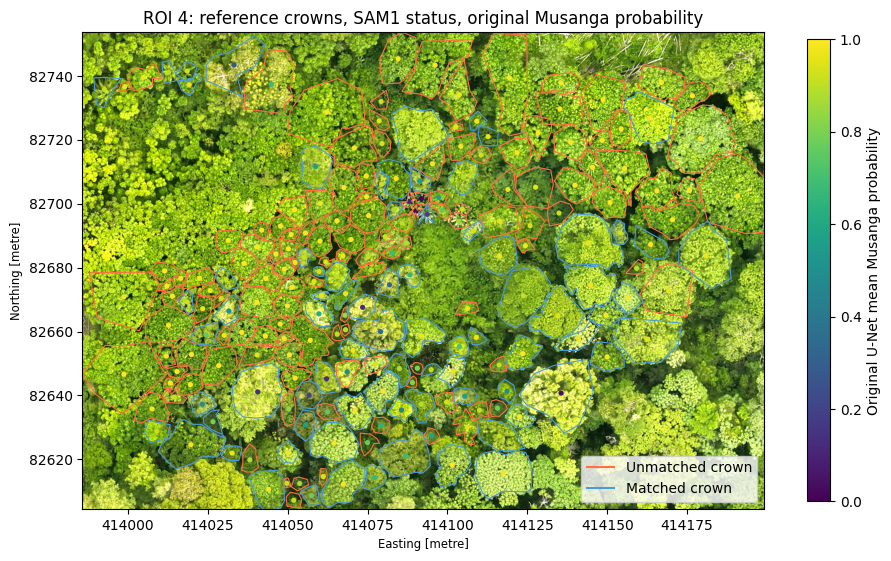

Saved diagnostics: /content/drive/MyDrive/Colab Notebooks/Musanga/V2/Crown/musanga_sam1_diagnostics


In [7]:
# 07 — Visualize matching gradients and ROI 4 with original U-Net probability
fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
axes[0].plot(QUARTILES.median_probability,QUARTILES.matched_rate,marker="o")
axes[0].set(xlabel="Median original U-Net Musanga probability (quartile)",
            ylabel="SAM1 IoU >=0.5 matched fraction",ylim=(0,1),
            title="Probability gradient in SAM1 crown matching")
axes[0].grid(alpha=.2)
for roi,g in ANALYSIS.groupby("ROI"):
    med=g.groupby("matched_iou_ge_0_5").musanga_mean_probability.mean()
    if len(med)==2:
        axes[1].plot([0,1],[med.loc[0],med.loc[1]],marker="o",label=f"ROI {roi}")
axes[1].set(xticks=[0,1],xticklabels=["Unmatched","Matched"],
            ylabel="Mean original U-Net Musanga probability",
            title="Matched versus unmatched within each ROI",ylim=(0,1))
axes[1].legend(fontsize=8,ncol=2)
fig.savefig(OUT/"03_musanga_match_association.png",dpi=180,bbox_inches="tight")
plt.show()

region=rois.geometry.iloc[4]
with rasterio.open(RGB) as ds:
    win=from_bounds(*region.bounds,transform=ds.transform).round_offsets().round_lengths()
    win=win.intersection(Window(0,0,ds.width,ds.height))
    rgb=ds.read([1,2,3],window=win).transpose(1,2,0).astype(float)
    bounds=ds.window_bounds(win)
lo,hi=np.nanpercentile(rgb,[2,98])
rgb=np.clip((rgb-lo)/max(hi-lo,1e-9),0,1)
fig,ax=plt.subplots(figsize=(11,8))
ax.imshow(rgb,extent=(bounds[0],bounds[2],bounds[1],bounds[3]))
r4=REF_CROWNS.loc[REF_CROWNS.ROI==4]
for status,outline in ((0,"#ff7043"),(1,"#4d9bd6")):
    group=r4.loc[r4.matched_iou_ge_0_5==status]
    if len(group):
        group.boundary.plot(ax=ax,color=outline,linewidth=0.8,
                            label="Unmatched" if status==0 else "Matched")
        centres=group.geometry.centroid
        ax.scatter(centres.x,centres.y,c=group.musanga_mean_probability,
                   vmin=0,vmax=1,cmap="viridis",s=14,edgecolor="none")
ax.set_xlim(bounds[0],bounds[2]);ax.set_ylim(bounds[1],bounds[3])
ax.set_aspect("equal");ax.set_title("ROI 4: reference crowns, SAM1 status, original Musanga probability")
import matplotlib.lines as mlines
legend=[mlines.Line2D([],[],color=c,label=l) for c,l in
        [("#ff7043","Unmatched crown"),("#4d9bd6","Matched crown")]]
ax.legend(handles=legend,loc="lower right")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0,1),cmap="viridis"),
             ax=ax,label="Original U-Net mean Musanga probability",shrink=.75)
fig.savefig(OUT/"03_ROI4_species_matching_map.png",dpi=200,bbox_inches="tight")
plt.show()
print("Saved diagnostics:",OUT)

## 08 — Final synthesis and scientific decision gate

Review (a) whether **unmatched** reference crowns have higher original-model probability within multiple ROIs, (b) whether an association remains when controlling for crown area and ROI, and (c) whether reference-only canopy has consistently elevated probability.

A positive signal justifies targeted manual verification of the species of missed crowns. A null signal suggests crown geometry, texture or annotation completeness is a more parsimonious explanation.

**Important:** source selection is verified in Section 01 before analysis; `probability_maps_M1_feathered_v2` is never used. The notebook cannot substitute a different model and never performs inference.

In [8]:
# 08 — Compact reproducible report
summary=(PER_ROI.pivot(index="ROI",columns="matched_iou_ge_0_5",
                       values="mean_prob").rename(columns={0:"unmatched_mean",1:"matched_mean"}))
summary["unmatched_minus_matched"]=summary.get("unmatched_mean",np.nan)-summary.get("matched_mean",np.nan)
print("=== Original Musanga probability: unmatched minus matched, per ROI ===")
display(summary.round(3))
summary.to_csv(OUT/"03_core_findings_by_ROI.csv")
print("Prediction source:",PROB_FILE)
print("Saved files:",OUT)
print("All outputs are diagnostic; historical U-Net/SAM1 files are unchanged.")

=== Original Musanga probability: unmatched minus matched, per ROI ===


matched_iou_ge_0_5,unmatched_mean,matched_mean,unmatched_minus_matched
ROI,,,
0,0.228,0.253,-0.025
1,0.400,0.349,0.050
2,0.621,0.552,0.068
3,0.647,0.538,0.109
4,0.923,0.798,0.125
5,0.431,0.328,0.103


Prediction source: /content/drive/MyDrive/Colab Notebooks/Musanga/KVO_work/KVO_04_final_multisite/probability_maps/Baego_musanga_probability_uint16_FULL.tif
Saved files: /content/drive/MyDrive/Colab Notebooks/Musanga/V2/Crown/musanga_sam1_diagnostics
All outputs are diagnostic; historical U-Net/SAM1 files are unchanged.


## 09 — Size-controlled Musanga association: omission versus merging

**Purpose:** Separate low crown IoU caused by absent predicted canopy from poor one-to-one delineation of crowns that SAM1 nevertheless covers.

Three tests, **all on existing Baego data and original non-M1 Musanga probabilities**:

1. **Size-controlled comparison:** split *reference* crown areas into three global tertiles; within each tertile, compare match rates across three Musanga-probability tertiles (show cell sample counts). This is descriptive, not independent statistical replication.
2. **Canopy omission versus delineation:** compute the proportion of each reference crown's area covered by the union of intersecting SAM polygons, **including polygons centred in the 40 m halo**. An IoU-unmatched crown with ≥50% SAM cover is primarily a delineation/matching problem; a crown with <10% SAM cover is a candidate omission.
3. **Potential merge associations:** for each crown, count how many *different reference crowns* are individually overlapped by the **same** SAM polygon covering ≥25% of each respective reference crown. This detects plausible multi-crown SAM polygons, not definitive merges.

Results are reported for the six ROIs and for ROI 4 separately. Comparisons are observational; spatial autocorrelation, crown size, canopy density and reference completeness remain confounders. The output directory is unchanged: `V2/Crown/musanga_sam1_diagnostics/`.

=== Size-controlled matching, SAM cover and multi-crown polygons ===


,size_tertile,musanga_tertile,n,match_rate,mean_sam_cover,omission_fraction,multicrown_fraction,median_ref_area,median_musanga_prob
0,small,low,89,0.303,0.594,0.348,0.416,15.552,0.092
1,small,medium,164,0.348,0.536,0.402,0.250,16.070,0.579
2,small,high,129,0.302,0.466,0.473,0.264,16.295,0.939
3,medium,low,113,0.602,0.787,0.168,0.434,39.727,0.085
4,medium,medium,130,0.538,0.686,0.231,0.308,36.542,0.506
5,medium,high,139,0.381,0.626,0.324,0.360,40.304,0.983
6,large,low,180,0.711,0.848,0.072,0.394,122.288,0.076
7,large,medium,88,0.727,0.837,0.080,0.398,96.847,0.403
8,large,high,114,0.632,0.785,0.167,0.491,99.222,0.985


=== Why reference crowns lack a one-to-one SAM match ===


,ROI,failure_class,n,mean_musanga_prob,median_area_m2,mean_sam_cover,multicrown_fraction
0,0,matched_IoU_ge_0.5,86,0.253,48.391,0.940,0.384
1,0,unmatched_but_covered_ge_50pct,41,0.256,30.364,0.933,0.902
2,0,unmatched_nearly_uncovered_lt_10pct,40,0.189,25.009,0.010,0.000
3,0,unmatched_partial_cover_10_to_50pct,8,0.285,24.636,0.227,0.250
4,1,matched_IoU_ge_0.5,79,0.349,62.645,0.915,0.177
5,1,unmatched_but_covered_ge_50pct,39,0.402,34.007,0.908,0.897
6,1,unmatched_nearly_uncovered_lt_10pct,36,0.420,25.846,0.007,0.000
7,1,unmatched_partial_cover_10_to_50pct,3,0.120,120.316,0.215,0.000
8,2,matched_IoU_ge_0.5,107,0.552,62.401,0.933,0.271
9,2,unmatched_but_covered_ge_50pct,43,0.575,28.988,0.930,0.977


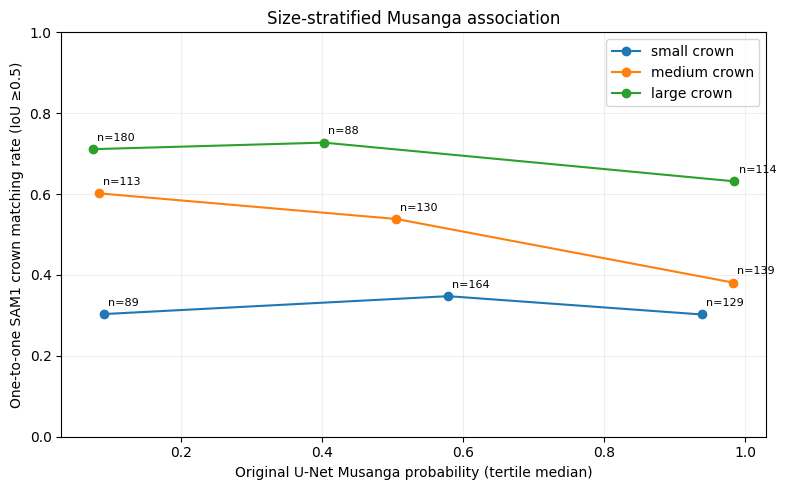

=== ROI 4 failure-mode counts and mean Musanga probability ===


,n,mean_probability,median_area_m2
failure_class,,,
matched_IoU_ge_0.5,79,0.798,46.415
unmatched_but_covered_ge_50pct,37,0.854,44.150
unmatched_nearly_uncovered_lt_10pct,92,0.948,29.711
unmatched_partial_cover_10_to_50pct,5,0.976,53.549


Saved Section 09 to: /content/drive/MyDrive/Colab Notebooks/Musanga/V2/Crown/musanga_sam1_diagnostics


In [9]:
# 09 — Coverage-aware, size-stratified SAM1 failure-mode diagnostics
# Runs after Sections 01-04. Requires: REF_CROWNS, sam, rois, OUT, pandas, numpy.
from shapely.ops import unary_union

def reference_coverage_and_merges(roi_id):
    region = rois.geometry.iloc[roi_id]
    ref_group = REF_CROWNS.loc[REF_CROWNS.ROI == roi_id].copy()
    # Use all halo-inclusive SAM polygons for footprint coverage; DO NOT centroid-filter.
    sam_geoms = list(sam[roi_id].geometry)
    ref_geoms = list(ref_group.geometry)
    nref, npred = len(ref_geoms), len(sam_geoms)
    inter = np.zeros((nref, npred), dtype=np.float64)
    for i, a in enumerate(ref_geoms):
        for j, b in enumerate(sam_geoms):
            if a.intersects(b):
                inter[i, j] = a.intersection(b).area
    ref_areas = np.asarray([a.area for a in ref_geoms], dtype=float)
    fractions = inter / np.maximum(ref_areas[:, None], 1.e-12)
    significant = fractions >= 0.25
    references_per_sam = significant.sum(axis=0)
    rows = []
    for i, a in enumerate(ref_geoms):
        touching = [sam_geoms[j] for j in np.flatnonzero(inter[i] > 0)]
        # Union matters: several overlapping SAM polygons must not inflate coverage.
        union = unary_union(touching).intersection(a) if touching else Polygon()
        covered = float(np.clip(union.area / a.area, 0, 1))
        associated = np.flatnonzero(significant[i])
        rows.append({
            "ROI": roi_id, "ref_local_id": int(ref_group.iloc[i].ref_local_id),
            "sam_cover_fraction": covered,
            "candidate_omission_lt_10pct": int(covered < 0.10),
            "unmatched_but_covered_ge_50pct": int(
                int(ref_group.iloc[i].matched_iou_ge_0_5) == 0 and covered >= 0.50),
            "significant_sam_count": int(len(associated)),
            "associated_with_multicrown_sam": int(
                bool(len(associated) and (references_per_sam[associated] >= 2).any()))
        })
    return pd.DataFrame(rows)

coverage = pd.concat(
    [reference_coverage_and_merges(roi_id) for roi_id in ROIS],
    ignore_index=True
)
details = REF_TABLE.merge(
    coverage, on=["ROI", "ref_local_id"], validate="one_to_one"
)
assert len(details) == len(REF_TABLE), "Reference crown coverage mismatch"
details["size_tertile"] = pd.qcut(
    details.ref_area_m2, q=3, labels=["small", "medium", "large"])
details["musanga_tertile"] = pd.qcut(
    details.musanga_mean_probability, q=3,
    labels=["low", "medium", "high"])

size_species = details.groupby(
    ["size_tertile", "musanga_tertile"], observed=True
).agg(
    n=("matched_iou_ge_0_5", "size"),
    match_rate=("matched_iou_ge_0_5", "mean"),
    mean_sam_cover=("sam_cover_fraction", "mean"),
    omission_fraction=("candidate_omission_lt_10pct", "mean"),
    multicrown_fraction=("associated_with_multicrown_sam", "mean"),
    median_ref_area=("ref_area_m2", "median"),
    median_musanga_prob=("musanga_mean_probability", "median")
).reset_index()

print("=== Size-controlled matching, SAM cover and multi-crown polygons ===")
display(size_species.round(3))
size_species.to_csv(OUT/"03_section09_size_by_musanga.csv", index=False)

details["failure_class"] = np.select(
    [
        details.matched_iou_ge_0_5.eq(1),
        details.sam_cover_fraction.lt(0.10),
        details.sam_cover_fraction.ge(0.50)
    ],
    [
        "matched_IoU_ge_0.5",
        "unmatched_nearly_uncovered_lt_10pct",
        "unmatched_but_covered_ge_50pct"
    ],
    default="unmatched_partial_cover_10_to_50pct"
)
by_roi = details.groupby(["ROI", "failure_class"]).agg(
    n=("ref_local_id", "size"),
    mean_musanga_prob=("musanga_mean_probability", "mean"),
    median_area_m2=("ref_area_m2", "median"),
    mean_sam_cover=("sam_cover_fraction", "mean"),
    multicrown_fraction=("associated_with_multicrown_sam", "mean")
).reset_index()
print("=== Why reference crowns lack a one-to-one SAM match ===")
display(by_roi.round(3))
by_roi.to_csv(OUT/"03_section09_failure_modes_by_roi.csv", index=False)
details.drop(columns=["size_tertile", "musanga_tertile", "failure_class"]).to_csv(
    OUT/"03_section09_crown_coverage_and_merges.csv", index=False)

# Compact size-controlled figure with cell sample sizes; not inferential.
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"small": "C0", "medium": "C1", "large": "C2"}
for size, group in size_species.groupby("size_tertile", observed=True):
    group = group.sort_values("median_musanga_prob")
    ax.plot(group.median_musanga_prob, group.match_rate,
            marker="o", label=f"{size} crown", color=colors[str(size)])
    for _, row in group.iterrows():
        ax.annotate(f"n={int(row.n)}",
                    (row.median_musanga_prob, row.match_rate),
                    xytext=(3, 6), textcoords="offset points", fontsize=8)
ax.set(xlabel="Original U-Net Musanga probability (tertile median)",
       ylabel="One-to-one SAM1 crown matching rate (IoU ≥0.5)",
       ylim=(0, 1), title="Size-stratified Musanga association")
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT/"03_section09_size_controlled_matching.png", dpi=180)
plt.show()

r4 = details.loc[details.ROI == 4]
print("=== ROI 4 failure-mode counts and mean Musanga probability ===")
display(r4.groupby("failure_class").agg(
    n=("ref_local_id", "size"),
    mean_probability=("musanga_mean_probability", "mean"),
    median_area_m2=("ref_area_m2", "median")
).round(3))
print("Saved Section 09 to:", OUT)